# Customer Segmentation Using K-Means Clustering on Mall Customer Dataset

---

In [ ]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')


In [ ]:
df = pd.read_csv("Mall_Customers.csv")

print(df.shape)
print(df.columns.tolist())

df.head(10)

(200, 5)
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [ ]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [ ]:
print("Missing Values per Column:")

print(df.isnull().sum())

Missing Values per Column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [ ]:
df_clean = df.drop('CustomerID', axis=1)

df_clean.head(10)

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40
5,Female,22,17,76
6,Female,35,18,6
7,Female,23,18,94
8,Male,64,19,3
9,Female,30,19,72


In [ ]:
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df_Clean)

print("Features after Min-Max Normalization (first 5 rows):")
print("Gender encoded: Female = 0  Male = 1")

pd.DataFrame(df_scaled, columns=df_Clean.columns).head()

Features after Min-Max Normalization (first 5 rows):
Gender encoded: Female = 0  Male = 1


,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1.0,0.019231,0.000000,0.387755
1,1.0,0.057692,0.000000,0.816327
2,0.0,0.038462,0.008197,0.051020
3,0.0,0.096154,0.008197,0.775510
4,0.0,0.250000,0.016393,0.397959


In [ ]:
inertia_list = []
silhouette_list = []
K_range = range(2,11)


for k in K_range:
    km = KMeans(n_clusters = k, init = "k-means++", random_state = 42, n_init = 10)
    km.fit(df_scaled)
    inertia_list.append(km.inertia_)
    silhouette_list.append(silhouette_score(df_scaled, km.labels_))

results = pd.DataFrame({
    "k" : list(K_range),
    "Inertia" : inertia_list,
    "silhouette_score" : silhouette_list
})
results


,k,Inertia,silhouette_score
0,2,37.272272,0.519462
1,3,29.552858,0.458353
2,4,22.390960,0.364166
3,5,19.062841,0.370895
4,6,16.413737,0.378966
5,7,14.221778,0.385247
6,8,12.243825,0.395193
7,9,10.600433,0.416675
8,10,9.668482,0.418250


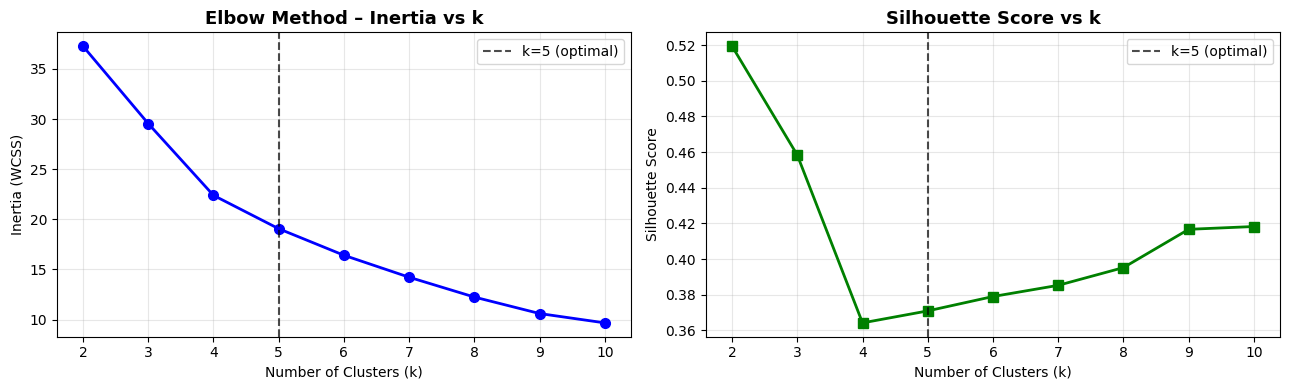

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(K_range, inertia_list, 'bo-', linewidth=2, markersize=7)
axes[0].axvline(x=5, color='black', linestyle='--', alpha=0.7, label='k=5 (optimal)')
axes[0].set_title('Elbow Method – Inertia vs k', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (WCSS)')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(K_range, silhouette_list, 'gs-', linewidth=2, markersize=7)
axes[1].axvline(x=5, color='black', linestyle='--', alpha=0.7, label='k=5 (optimal)')
axes[1].set_title('Silhouette Score vs k', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42)
df['Cluster'] = kmeans.fit_predict(df_scaled)

sil_score = silhouette_score(df_scaled, df['Cluster'])
print(f"Clustering Complete!")
print(f"Final Inertia: {kmeans.inertia_:.4f}")
print(f"Silhouette Score: {sil_score:.4f}")

Clustering Complete!
Final Inertia: 19.0628
Silhouette Score: 0.3709


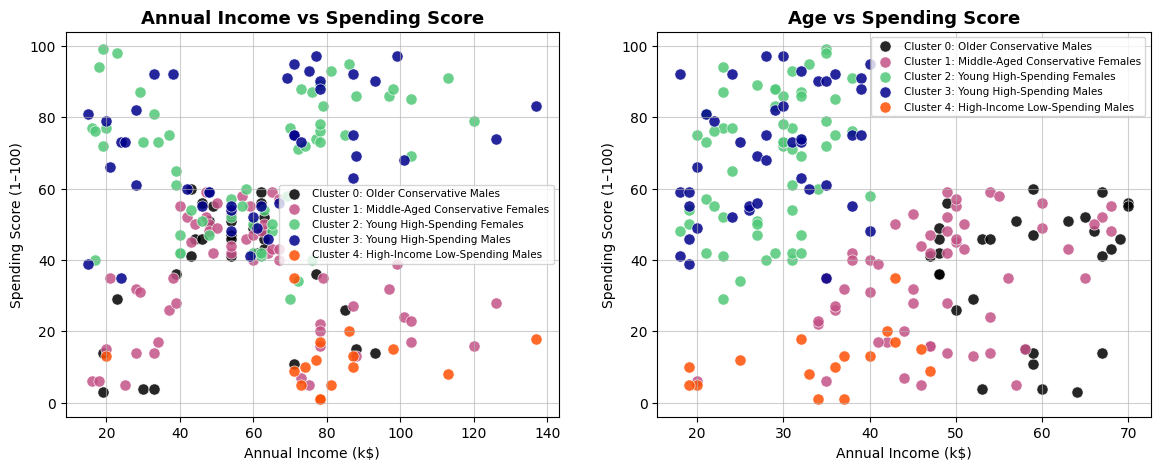

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i in range (5):
   mask = df['Cluster'] == i
   axes[0].scatter(
        df.loc[mask, 'Annual Income (k$)'],
        df.loc[mask, 'Spending Score (1-100)'],
        c=COLORS[i], label=f'Cluster {i}: {segment_names[i]}',
        s=65, alpha=0.85, edgecolors='white', linewidth=0.5
    )

axes[0].set_title('Annual Income vs Spending Score', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1–100)')
axes[0].legend(fontsize=7.5)
axes[0].grid(alpha=0.6)



for i in range(5):
    mask = df['Cluster'] == i
    axes[1].scatter(
        df.loc[mask, 'Age'],
        df.loc[mask, 'Spending Score (1-100)'],
        c=COLORS[i], label=f'Cluster {i}: {segment_names[i]}',
        s=65, alpha=0.85, edgecolors='white', linewidth=0.5
    )

axes[1].set_title('Age vs Spending Score', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Annual Income (k$)')
axes[1].set_ylabel('Spending Score (1–100)')
axes[1].legend(fontsize=7.5)
axes[1].grid(alpha=0.6)



--- Cluster Profiles (Average Values per Group) ---


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,
0,84.366667,58.166667,53.633333,37.566667
1,94.818182,48.109091,58.818182,34.781818
2,100.210526,28.438596,59.666667,67.684211
3,100.809524,28.690476,60.904762,70.238095
4,150.500000,34.562500,81.812500,12.000000


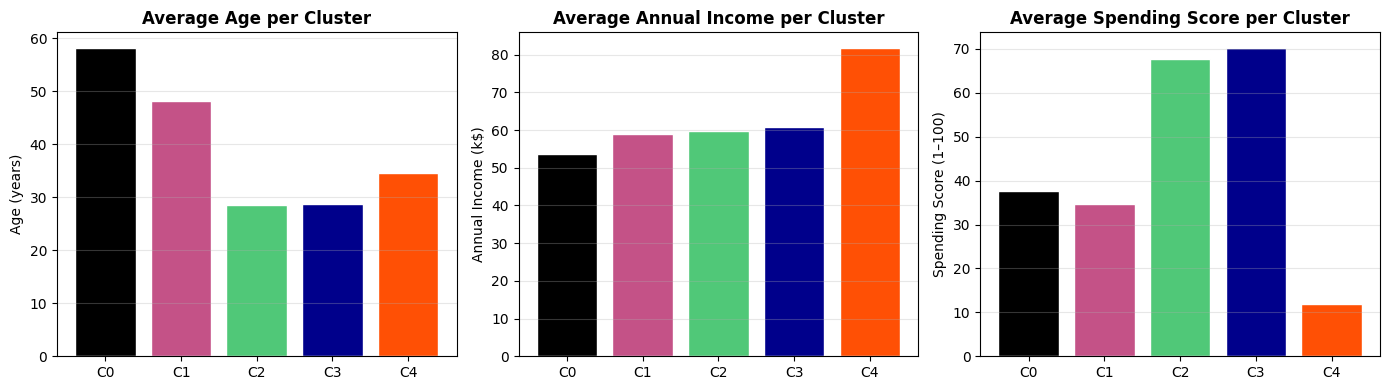

In [ ]:
print("--- Cluster Profiles (Average Values per Group) ---")
cluster_summary = df.groupby('Cluster').mean(numeric_only=True)

cluster_ids = [f'C{i}' for i in range(5)]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].bar(cluster_ids, profile['Avg_Age'], color=COLORS, edgecolor='white')
axes[0].set_title('Average Age per Cluster', fontweight='bold')
axes[0].set_ylabel('Age (years)')
axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(cluster_ids, profile['Avg_Annual_Income_kUSD'], color=COLORS, edgecolor='white')
axes[1].set_title('Average Annual Income per Cluster', fontweight='bold')
axes[1].set_ylabel('Annual Income (k$)')
axes[1].grid(axis='y', alpha=0.3)

axes[2].bar(cluster_ids, profile['Avg_Spending_Score'], color=COLORS, edgecolor='white')
axes[2].set_title('Average Spending Score per Cluster', fontweight='bold')
axes[2].set_ylabel('Spending Score (1–100)')
axes[2].grid(axis='y', alpha=0.3)

display(cluster_summary)


plt.tight_layout()
plt.show()



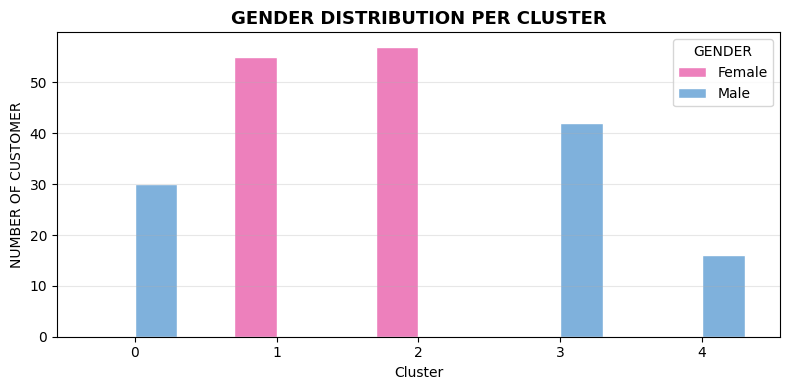

In [ ]:
gender_counts = df.groupby(['Cluster', 'Gender']).size().unstack(fill_value=0)
gender_counts.plot(kind='bar', color=["#ed80bc", "#7fb1dc"],
                   figsize=(8, 4), edgecolor='white', width=0.6)
plt.title('GENDER DISTRIBUTION PER CLUSTER', fontsize=13, fontweight='bold')
plt.xlabel('Cluster')
plt.ylabel('NUMBER OF CUSTOMER')
plt.xticks(rotation=0)
plt.legend(title='GENDER')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

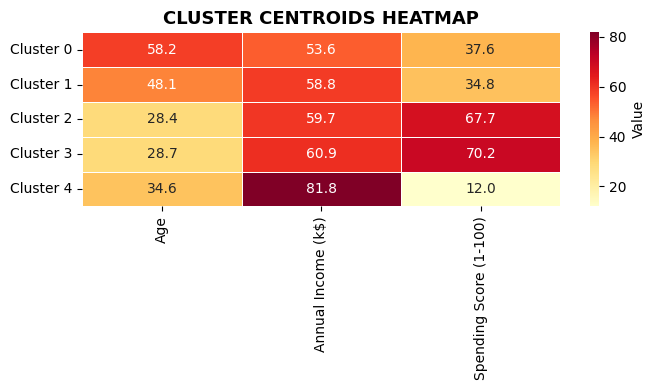

In [ ]:
centroids_df = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=df_clean.columns
).drop(columns=['Gender'])
centroids_df.index = [f'Cluster {i}' for i in range(5)]

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(centroids_df, annot=True, fmt='.1f', cmap='YlOrRd',
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Value'})
ax.set_title('CLUSTER CENTROIDS HEATMAP', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
summary = df.groupby('Cluster').mean(numeric_only=True)
print('\nCustomer Segment Interpretation')
print('_______________________________')

print('Cluster 0 -> Average Customers')
print('Cluster 1 -> High Income High Spenders')
print('Cluster 2 -> Low Income Low Spenders')
print('Cluster 3 -> Young Moderate Spenders')
print('Cluster 4 -> High Income Low Spenders')

print(summary)


Customer Segment Interpretation
_______________________________-
Cluster 0 -> Average Customers
Cluster 1 -> High Income High Spenders
Cluster 2 -> Low Income Low Spenders
Cluster 3 -> Young Moderate Spenders
Cluster 4 -> High Income Low Spenders
         CustomerID        Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                                   
0         84.366667  58.166667           53.633333               37.566667
1         94.818182  48.109091           58.818182               34.781818
2        100.210526  28.438596           59.666667               67.684211
3        100.809524  28.690476           60.904762               70.238095
4        150.500000  34.562500           81.812500               12.000000
